c:\Users\Paimon\miniconda3\envs\ml_project\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Paimon\.cache\kagglehub\datasets\sakshigoyal7\credit-card-customers\versions\1
Unknown in CLIENTNUM: 0 
Unknown in Attrition_Flag: 0 
Unknown in Customer_Age: 0 
Unknown in Gender: 0 
Unknown in Dependent_count: 0 
Unknown in Education_Level: 1519 
Unknown in Marital_Status: 749 
Unknown in Income_Category: 1112 
Unknown in Card_Category: 0 
Unknown in Months_on_book: 0 
Unknown in Total_Relationship_Count: 0 
Unknown in Months_Inactive_12_mon: 0 
Unknown in Contacts_Count_12_mon: 0 
Unknown in Credit_Limit: 0 
Unknown in Total_Revolving_Bal: 0 
Unknown in Avg_Open_To_Buy: 0 
Unknown in Total_Amt_Chng_Q4_Q1: 0 
Unknown in Total_Trans_Amt: 0 
Unknown in Total_Trans_Ct: 0 
Unknown in Total_Ct_Chng_Q4_Q1: 0 
Unknown in Avg_Utilization_Ratio: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1: 0 
Unknown in Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contact

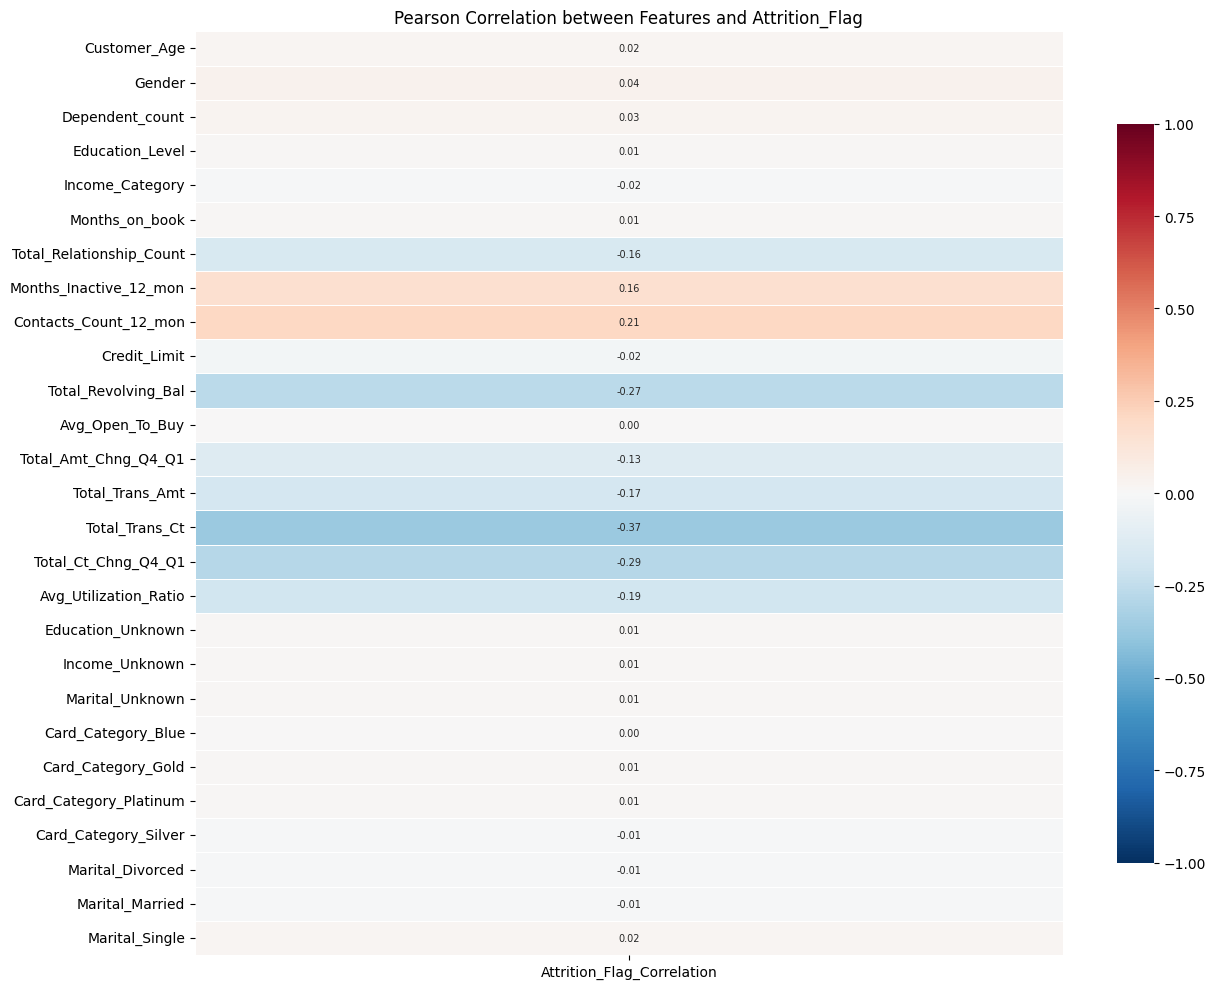

                     feature        score         pvalue  mutual_info  \
0             Total_Trans_Ct  1304.840615  4.672547e-265     0.117308   
1        Total_Ct_Chng_Q4_Q1   724.081801  7.826216e-153     0.097107   
2        Total_Revolving_Bal   624.638229  7.200815e-133     0.086718   
3      Contacts_Count_12_mon   357.053749   5.766715e-78     0.031237   
4      Avg_Utilization_Ratio   298.439252   1.074262e-65     0.056820   
5            Total_Trans_Amt   251.300721   9.267982e-56     0.158251   
6     Months_Inactive_12_mon   207.190324   2.099911e-46     0.020610   
7   Total_Relationship_Count   204.922922   6.377533e-46     0.012831   
8       Total_Amt_Chng_Q4_Q1   137.395987   1.772444e-31     0.031095   
9            Dependent_count     7.760686   5.351984e-03     0.002122   
10              Credit_Limit     4.658394   3.093137e-02     0.000305   
11              Customer_Age     2.412416   1.204155e-01     0.000000   
12            Months_on_book     0.534546   4.64723

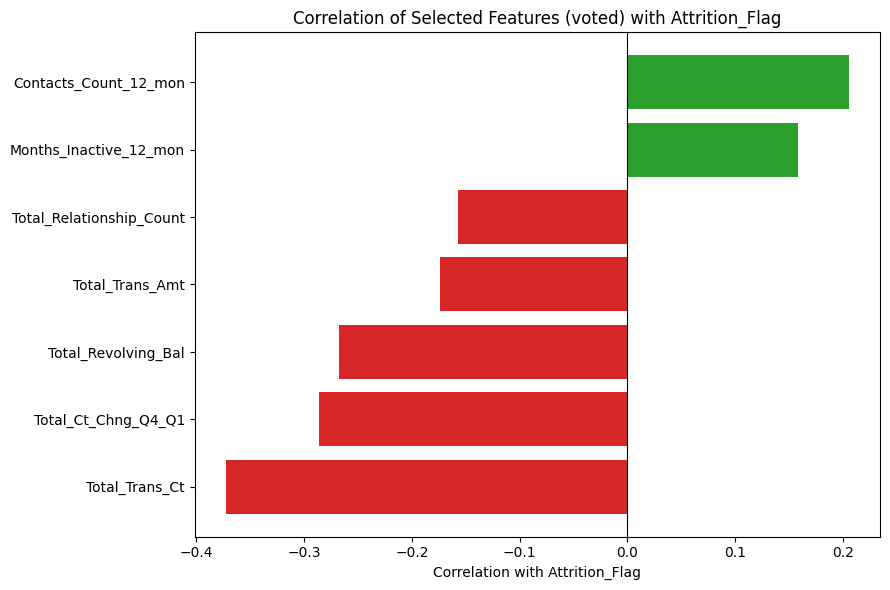

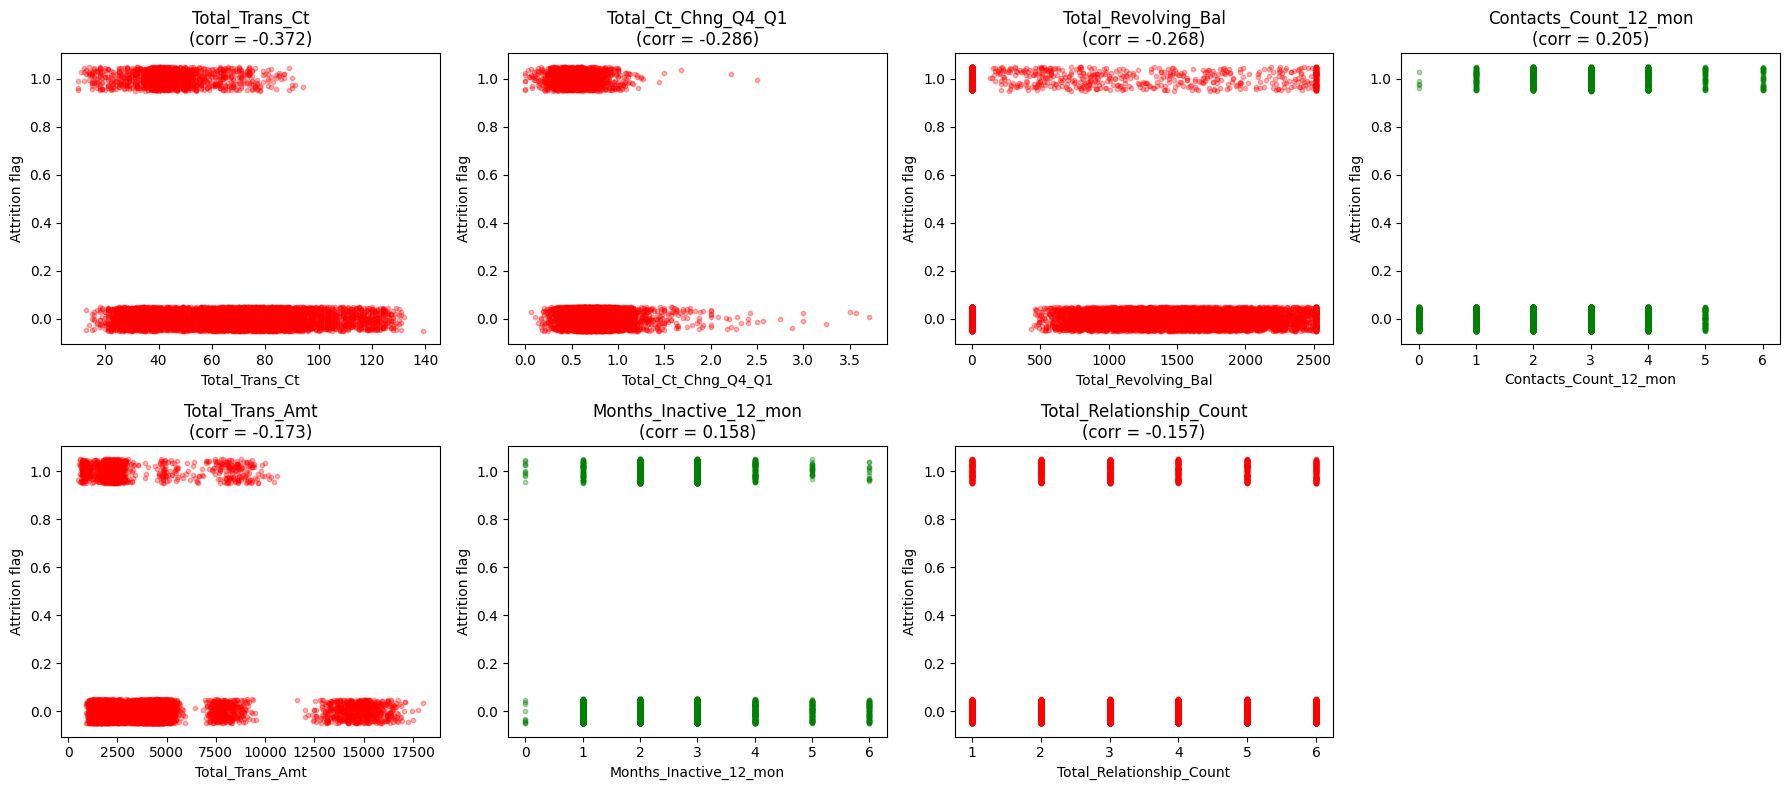

ฟีเจอร์: 25
Train: 8101 | Test: 2026

Income_Category             0.563
Card_Category_Blue          0.516
Card_Category_Silver        0.441
Gender                      0.421
Card_Category_Gold          0.234
Total_Trans_Amt             0.172
Card_Category_Platinum      0.106
Total_Trans_Ct              0.076
Total_Relationship_Count    0.071
Dependent_count             0.068
                 feature       score        pvalue  mutual_info
         Income_Category 3818.741260  0.000000e+00     0.211580
      Card_Category_Blue 2860.832605  0.000000e+00     0.116305
    Card_Category_Silver 1863.773769  0.000000e+00     0.084387
                  Gender 1793.463987  0.000000e+00     0.130455
      Card_Category_Gold  519.128770 1.972602e-111     0.030937
         Total_Trans_Amt  242.378319  7.156694e-54     0.106803
  Card_Category_Platinum   75.218274  5.036403e-18     0.006265
          Total_Trans_Ct   46.951240  7.810232e-12     0.039888
Total_Relationship_Count   42.747424  6.605692

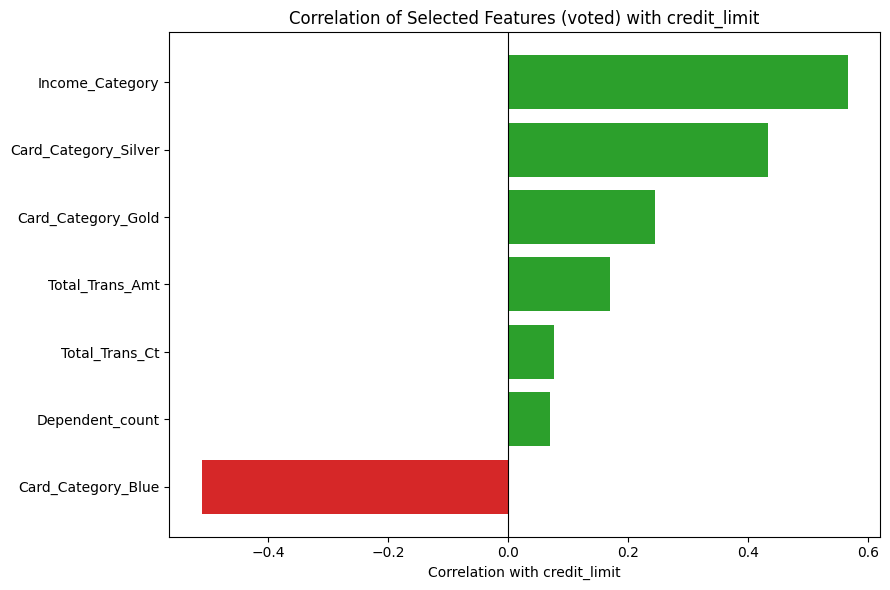

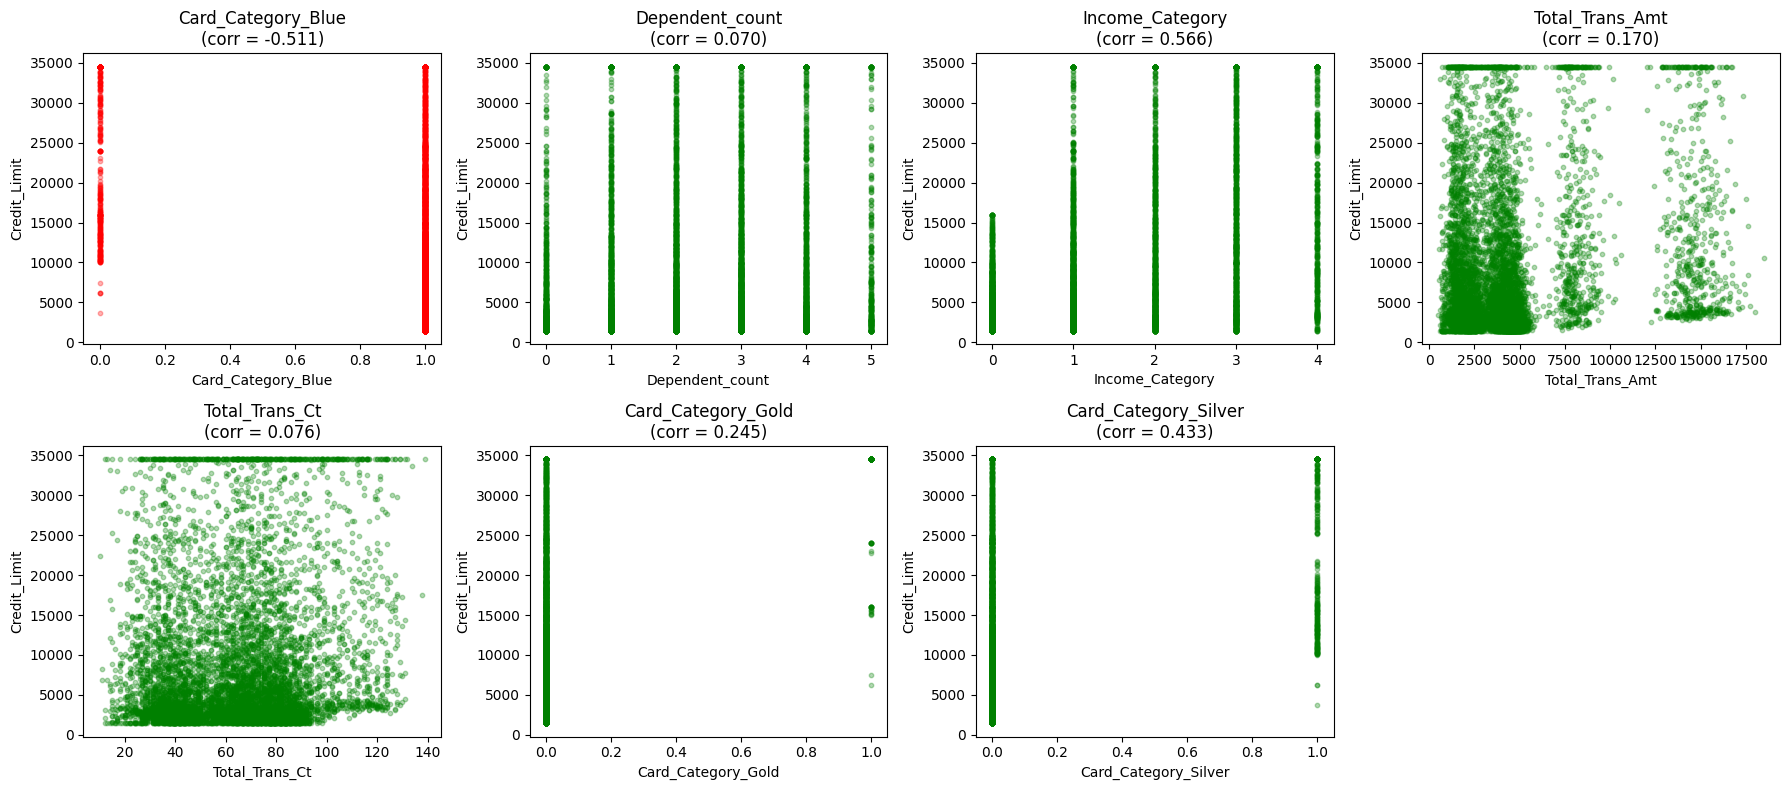

R² each fold: [0.5178384  0.55896333 0.51699789 0.55879163 0.56659464]
Mean R²: 0.5438 (+/- 0.0218)


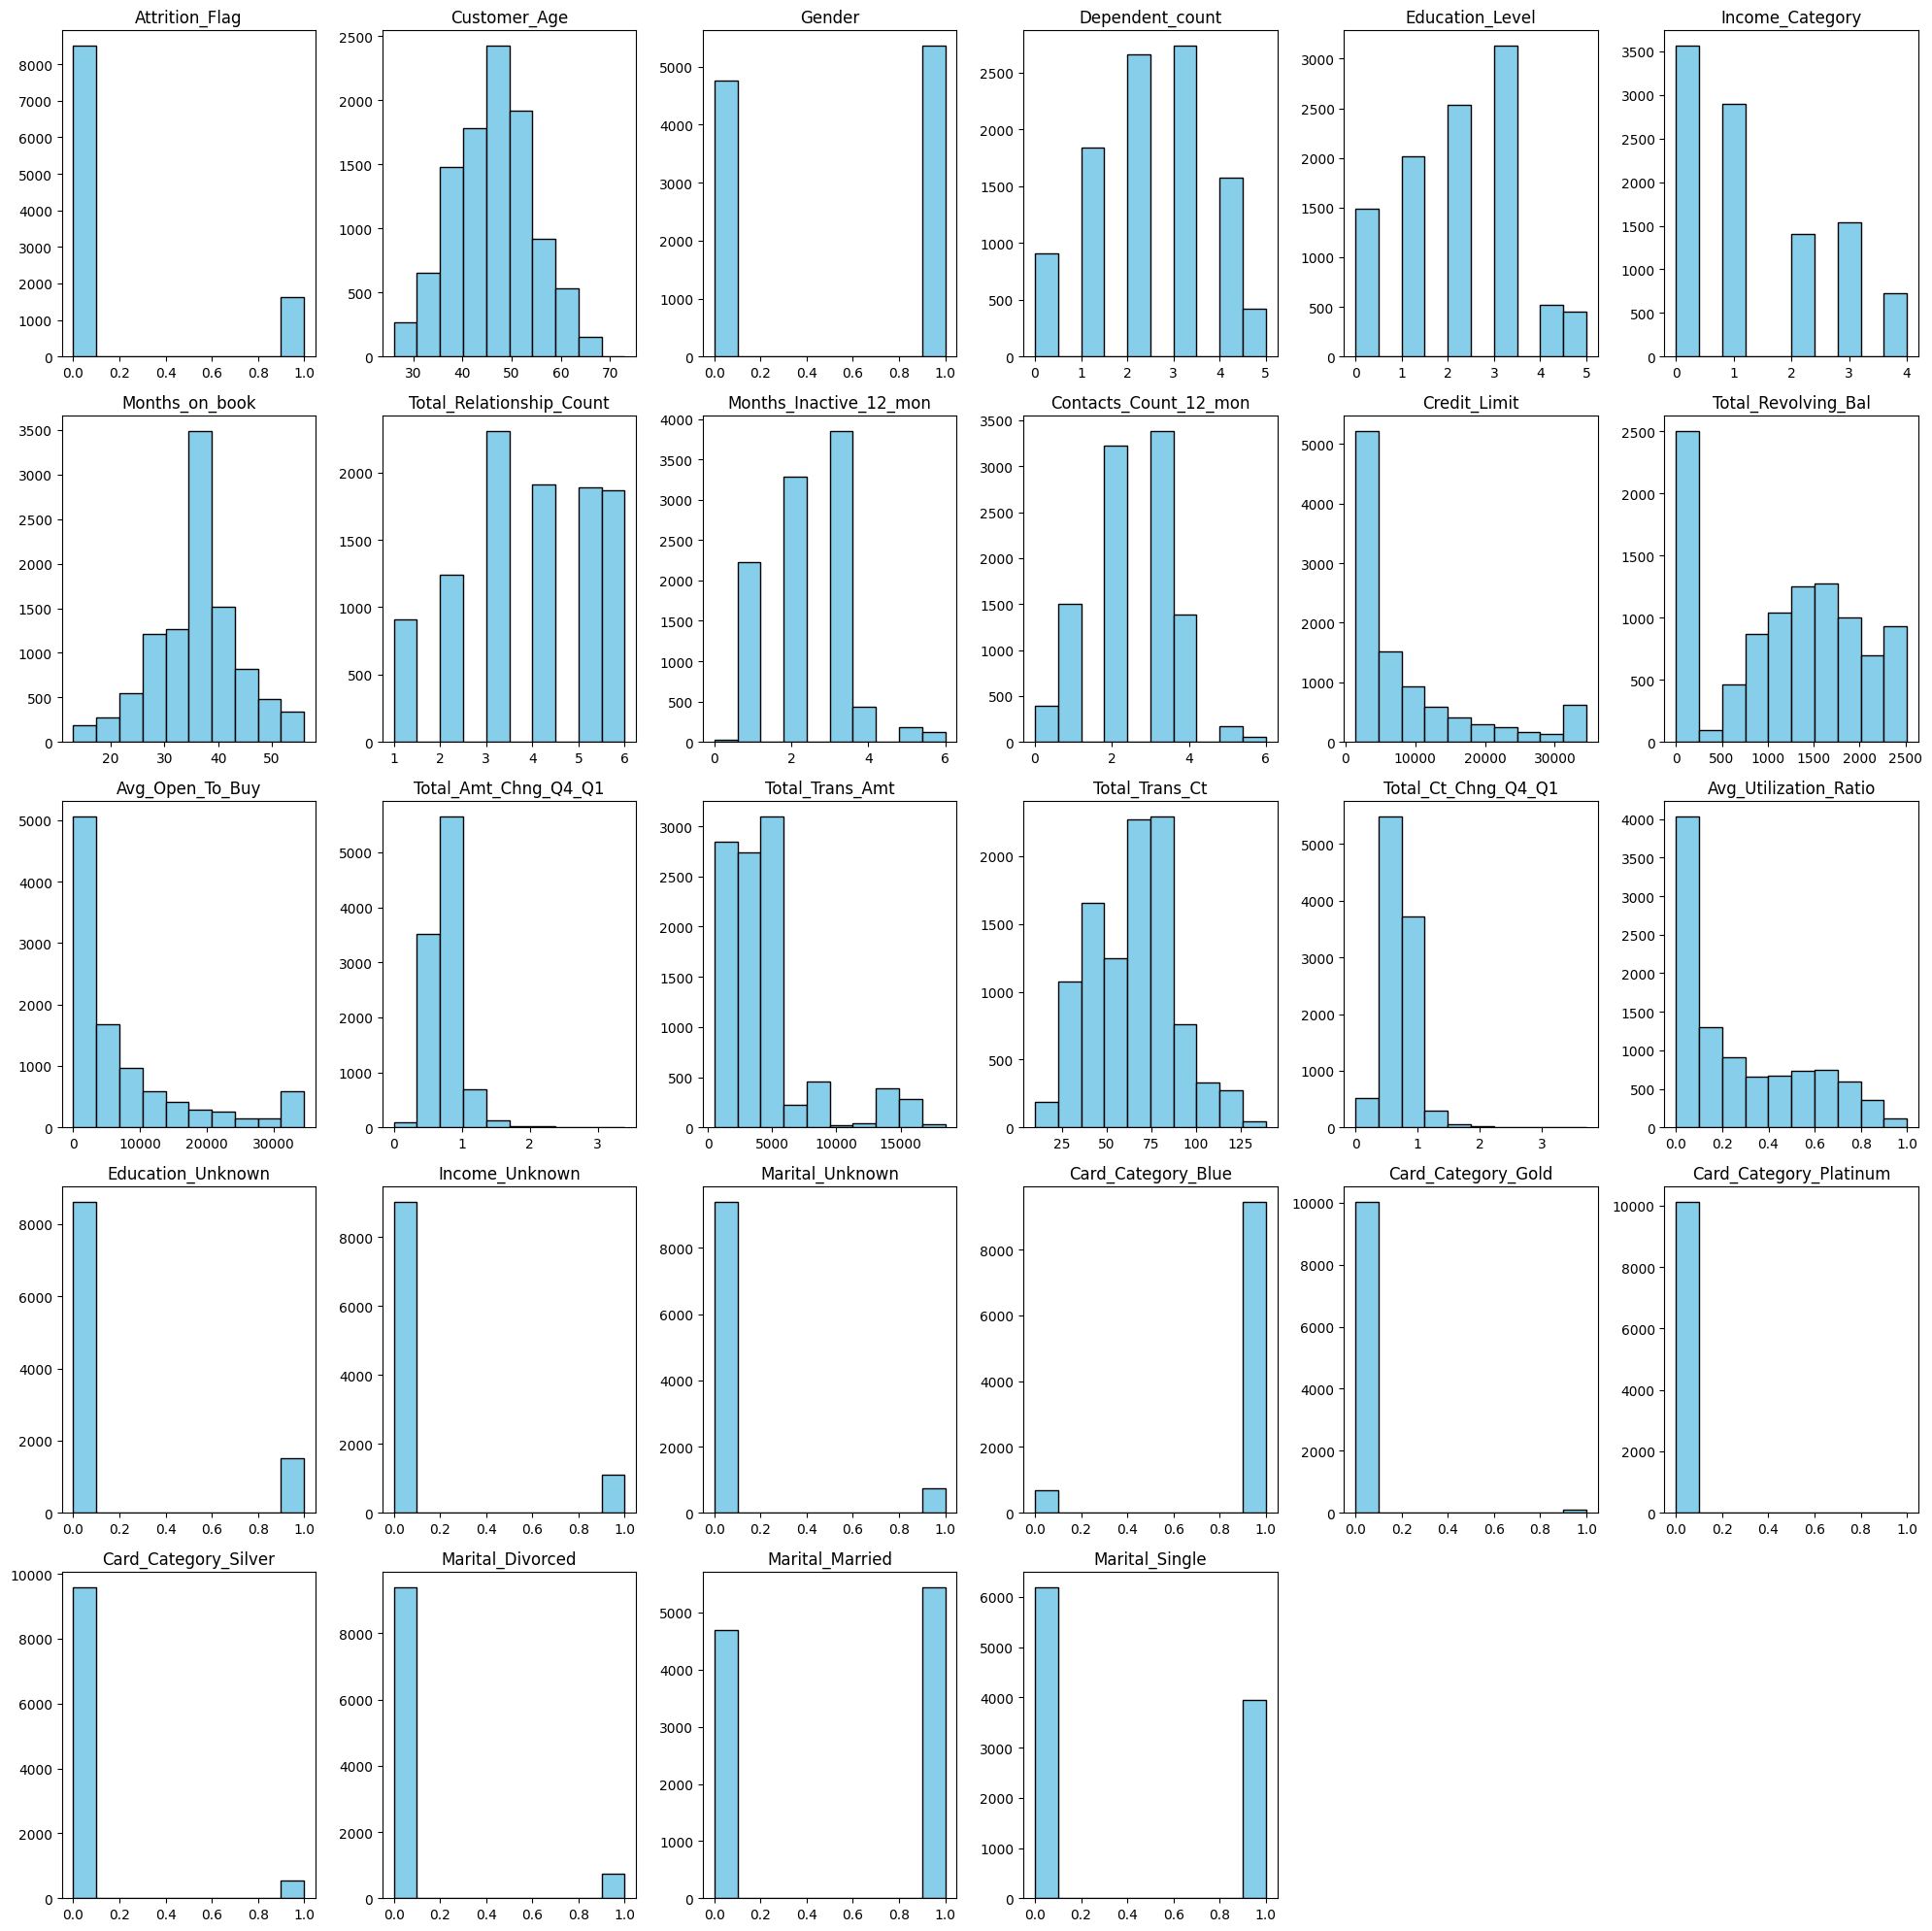

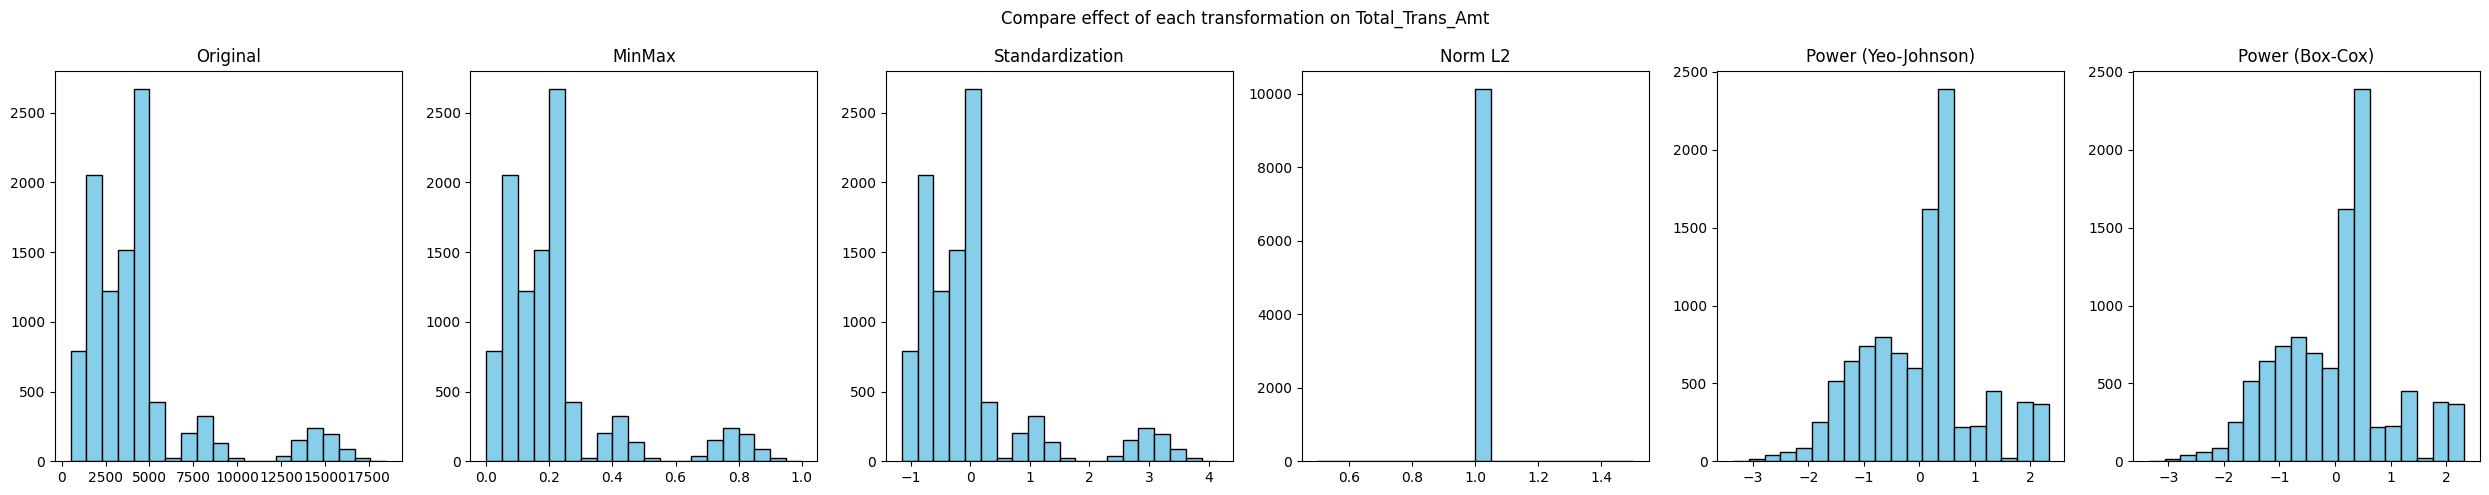

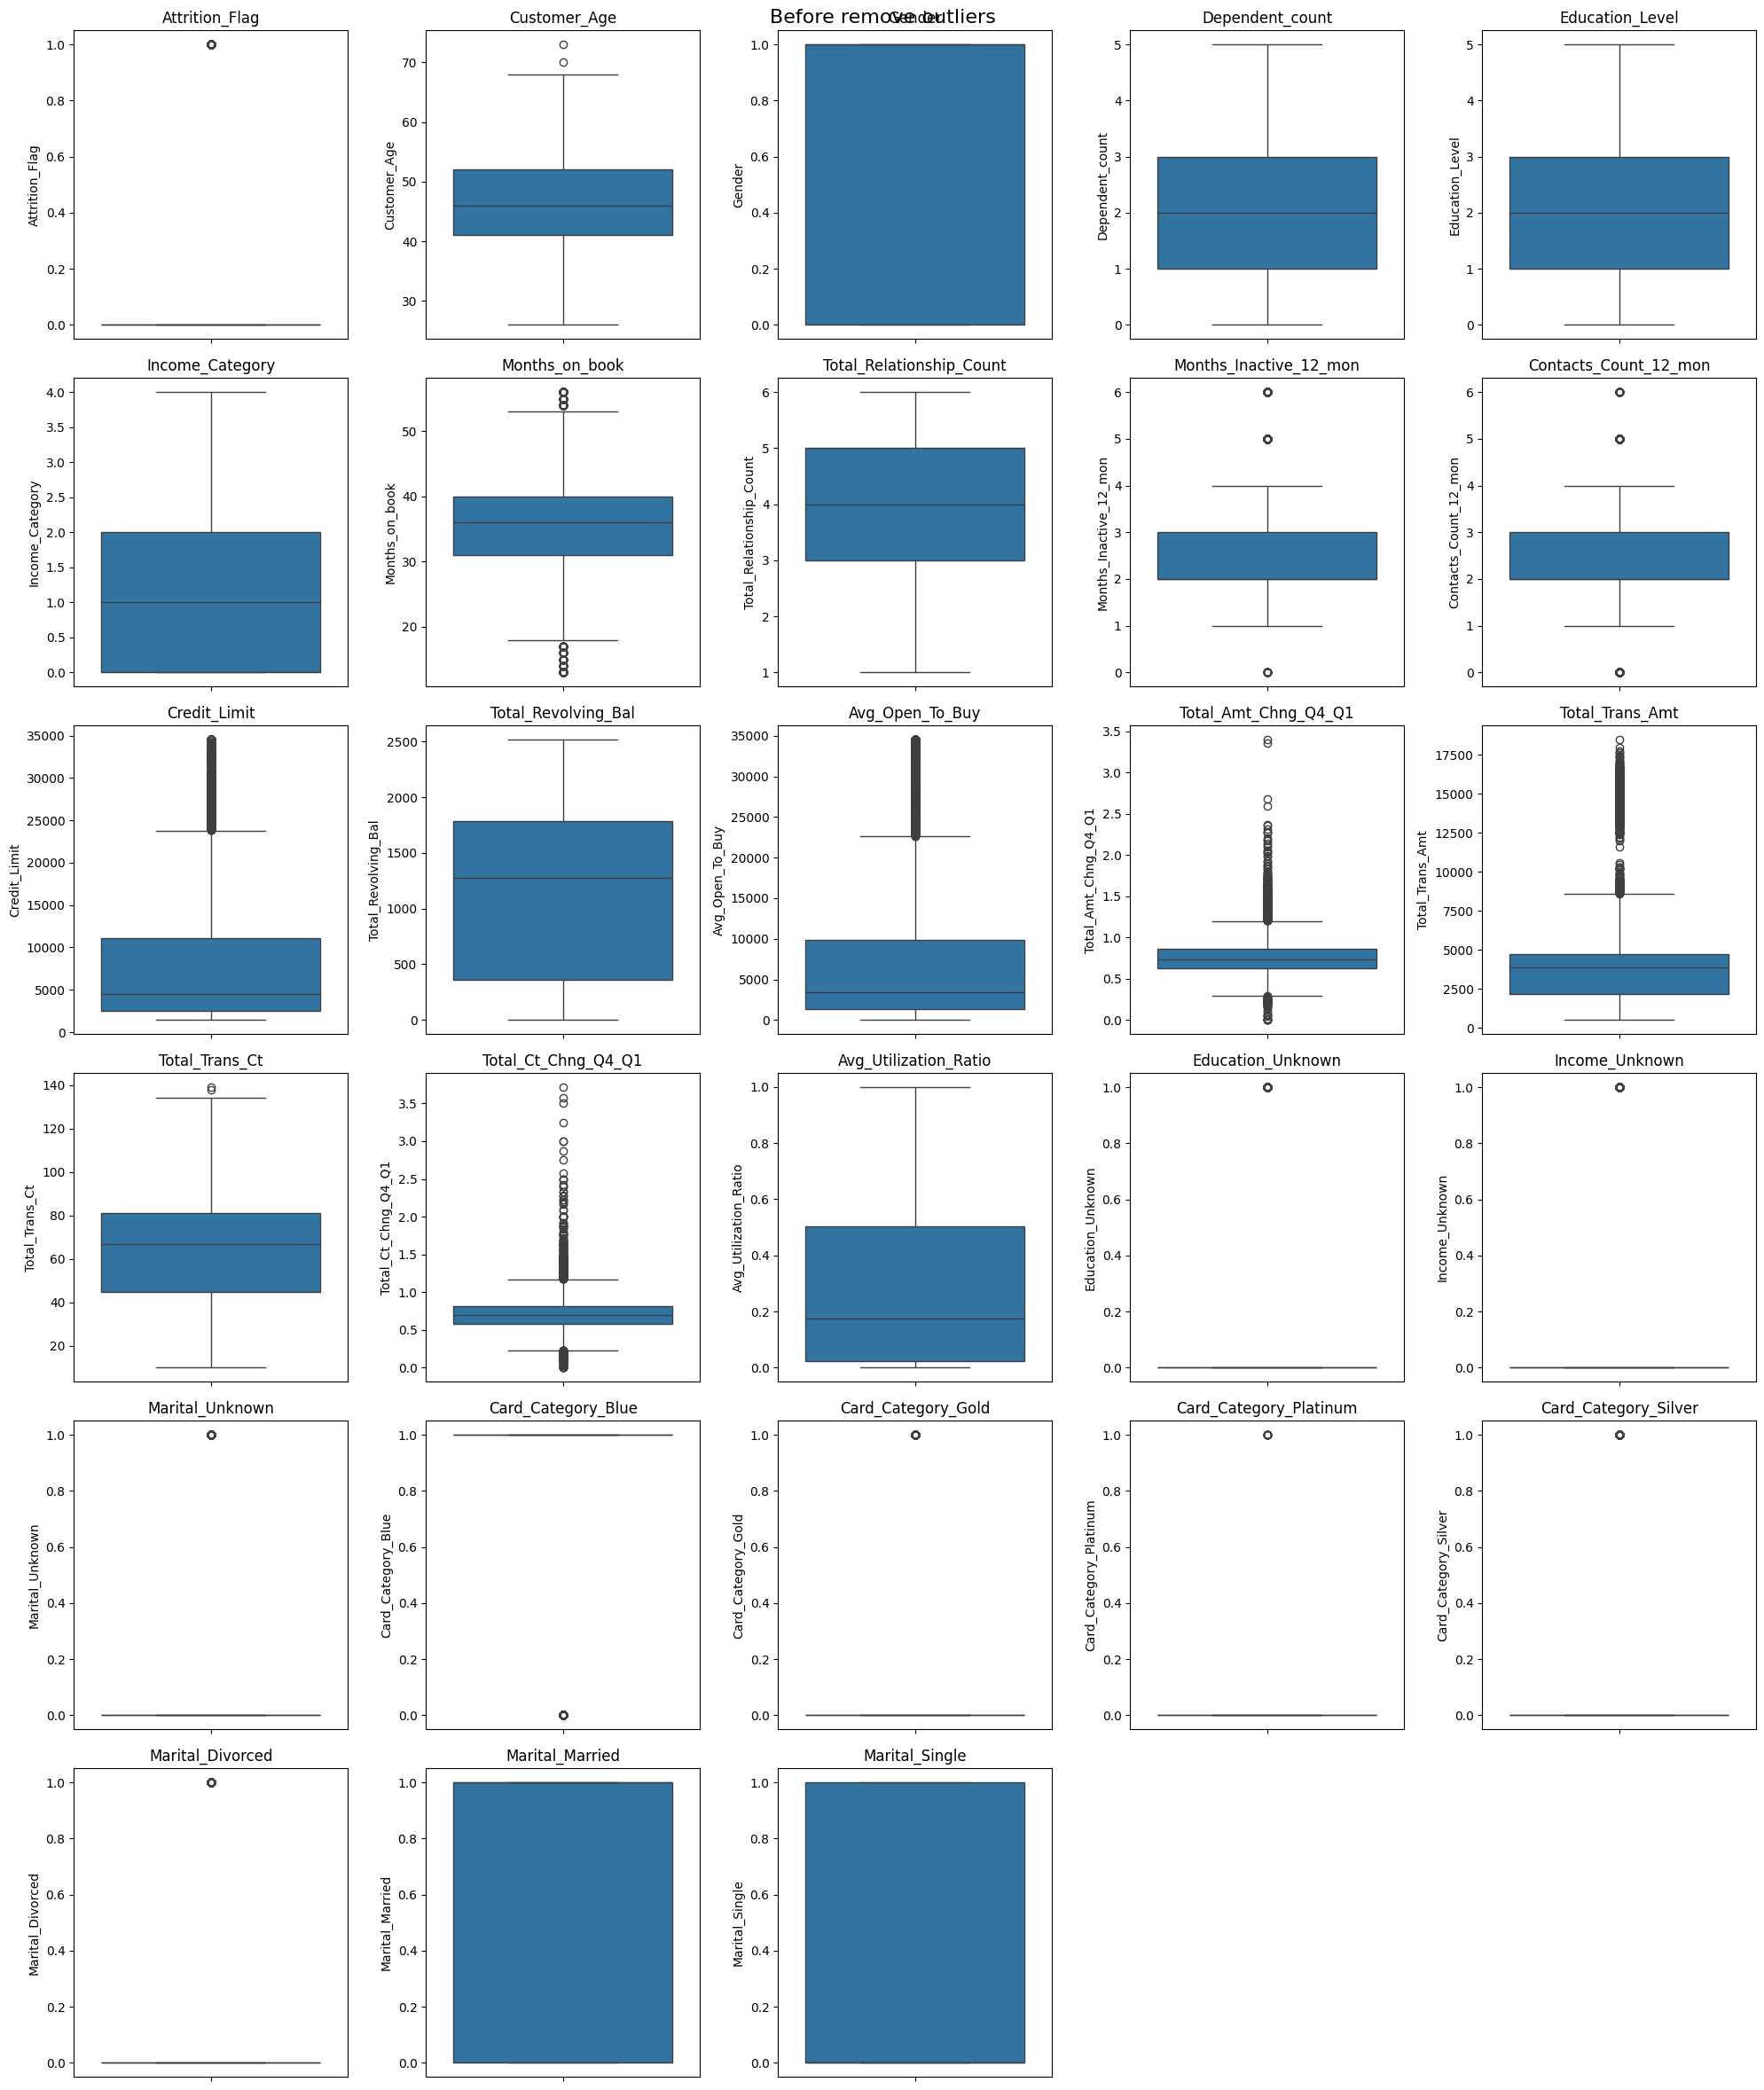

In [2]:
import import_ipynb
import data_analysis
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import HuberRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [3]:
reg_features = ['Income_Category', 'Card_Category_Blue', 'Total_Trans_Amt',
                 'Card_Category_Silver', 'Total_Trans_Ct', 'Card_Category_Gold',
                 'Dependent_count']

Xr_train = data_analysis.Xr_train[reg_features]
Xr_test = data_analysis.Xr_test[reg_features]
yr_train = data_analysis.yr_train
yr_test = data_analysis.yr_test

continuous_cols = ['Total_Trans_Amt', 'Total_Trans_Ct', 'Dependent_count']
scaler = StandardScaler()
Xr_train_scaled = Xr_train.copy()
Xr_test_scaled = Xr_test.copy()
Xr_train_scaled[continuous_cols] = scaler.fit_transform(Xr_train[continuous_cols])
Xr_test_scaled[continuous_cols] = scaler.transform(Xr_test[continuous_cols])

In [4]:
class HuberRegressionScratch:
    def __init__(self, delta=1500.0, max_iter=50, tol=1e-6):
        self.delta = delta
        self.max_iter = max_iter
        self.tol = tol
        self.coef_ = None
        self.intercept_ = None
        self.loss_history = []

    def _huber_loss(self, residual):
        abs_r = np.abs(residual)
        quad = 0.5 * residual**2
        lin = self.delta * (abs_r - 0.5*self.delta)
        return np.mean(np.where(abs_r <= self.delta, quad, lin))

    def fit(self, X, y):
        m, n = X.shape
        X_b = np.c_[np.ones((m, 1)), X]
        y = np.asarray(y).ravel()
        theta = np.zeros(n + 1)

        for i in range(self.max_iter):
            residual = X_b @ theta - y
            abs_r = np.abs(residual)
            weights = np.where(abs_r <= self.delta, 1.0, self.delta / (abs_r + 1e-8))
            W = np.diag(weights)

            theta_new = np.linalg.solve(X_b.T @ W @ X_b, X_b.T @ W @ y)

            self.loss_history.append(self._huber_loss(residual))

            if np.linalg.norm(theta_new - theta) < self.tol:
                theta = theta_new
                break
            theta = theta_new

        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        return X @ self.coef_ + self.intercept_

In [5]:
huber_model = HuberRegressionScratch(delta=1500.0, max_iter=50)
huber_model.fit(Xr_train_scaled.values, yr_train)

y_pred_huber = huber_model.predict(Xr_test_scaled.values)

print("R² =", r2_score(yr_test, y_pred_huber))
print("MSE =", mean_squared_error(yr_test, y_pred_huber))
print("MAE =", mean_absolute_error(yr_test, y_pred_huber))

R² = 0.5108633622978176
MSE = 40489125.06788026
MAE = 4107.376588139658


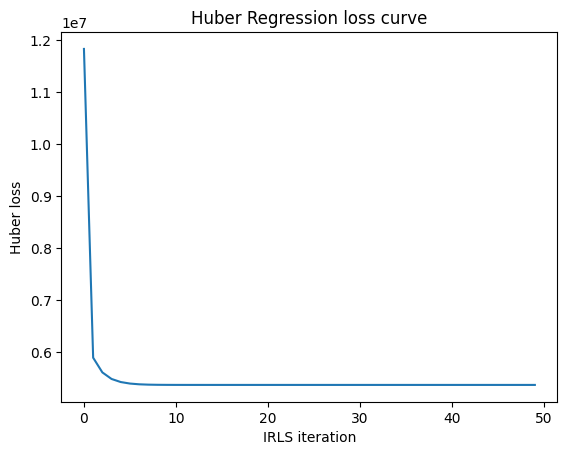

In [6]:
# loss curve
plt.plot(huber_model.loss_history)
plt.xlabel('IRLS iteration')
plt.ylabel('Huber loss')
plt.title('Huber Regression loss curve')
plt.show()

In [7]:
sk_huber = HuberRegressor(epsilon=1.35, max_iter=2000)
sk_huber.fit(Xr_train_scaled.values, yr_train)
y_pred_sk_huber = sk_huber.predict(Xr_test_scaled.values)

print("sklearn R² =", r2_score(yr_test, y_pred_sk_huber))

sklearn R² = 0.5195408216410922
